# Laurence Fishburne y sus colaboradores: un grafo visto como kernel
Análisis y Ciencia de Datos · UNIS · Parte individual · **Nohel Estrada**

Si $B$ es la matriz actores × películas, $A = BB^\top$ cuenta películas compartidas. Es la misma idea que el kernel del
*random forest* de la parte grupal: allá dos filas se parecen si caen en las mismas hojas; aquí dos actores se parecen si
salen en las mismas películas. Cada película juega el papel de una hoja.

**Para correrlo:** basta con el cache de `cache/`. Solo si falta algún JSON hace falta exportar `TMDB_API_KEY`
(no está en el repositorio).

In [1]:
import itertools
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from graph import Graph
from tmdb_api import TMDBAPIUtils

ACTOR = "Laurence Fishburne"
LIMIT = 5
VENTANA = ("1975-01-01", "2025-12-31")
tmdb = TMDBAPIUtils(cache="cache")

## I.2 La clase `Graph` (en `graph.py`)
Lista de adyacencia `adj[a][b] = peso`. Al agregar $(a,b)$ se actualizan `adj[a][b]` y `adj[b][a]`, así que $(a,b)$ y
$(b,a)$ son la misma arista. Una prueba pequeña:

In [2]:
t = Graph()
for nodo in [(10, "x"), (20, "y"), (30, "z"), (10, "x otra vez")]:
    t.add_node(nodo)
for a, b in [(10, 20), (20, 10), (20, 30)]:
    t.add_edge(a, b)
M, orden = t.adjacency()
print(t.total_nodes(), "nodos,", t.total_edges(), "aristas, mayor grado:", t.max_degree_nodes())
print(orden, "\n", M)

3 nodos, 2 aristas, mayor grado: {20: 2}
[10, 20, 30] 
 [[0. 2. 0.]
 [2. 0. 1.]
 [0. 1. 0.]]


## I.3 `TMDBAPIUtils` (en `tmdb_api.py`)
Cada respuesta se guarda como JSON en `cache/`. `get_movie_cast` filtra `0 ≤ order ≤ limit−1` y quita `exclude_ids`;
`get_movie_credits_for_person` filtra por fecha (el API no lo hace), quita documentales (género 99) y papeles en los
que el actor hace de sí mismo.

In [3]:
encontrado = tmdb.search_person(ACTOR)[0]
SEMILLA = encontrado["id"]
print(f"{encontrado['name']} -> id {SEMILLA}")

Laurence Fishburne -> id 2975


## I.4 Construcción del grafo
Una película **cuenta** para un actor si salió en la ventana 1975–2025 y el actor tiene `order < 5`.

In [4]:
def cuentan(persona):
    # una persona puede aparecer dos veces en la misma película (dos personajes): se cuenta una vez
    unicas = {p["id"]: p for p in tmdb.get_movie_credits_for_person(persona, *VENTANA)
              if p["order"] is not None and p["order"] < LIMIT}
    return list(unicas.values())


def construir_grafo():
    g = Graph()
    g.add_node((SEMILLA, ACTOR))                                   # (a)
    for peli in cuentan(SEMILLA):                                  # (b)
        for actor in tmdb.get_movie_cast(peli["id"], LIMIT, exclude_ids=[SEMILLA]):
            g.add_node((actor["id"], actor["name"]))
    creditos = {n: cuentan(n) for n in g.names}                    # (c)
    por_peli = {}
    for n, pelis in creditos.items():
        for p in pelis:
            por_peli.setdefault(p["id"], {"titulo": f"{p['title']} ({p['release_date'][:4]})", "actores": set()})
            por_peli[p["id"]]["actores"].add(n)
    for info in por_peli.values():
        for a, b in itertools.combinations(sorted(info["actores"]), 2):   # una vez por película y pareja
            g.add_edge(a, b)
    return g, creditos, por_peli


g, creditos, por_peli = construir_grafo()
A, orden = g.adjacency()
pos_de = {n: i for i, n in enumerate(orden)}
grado = {n: len(v) for n, v in g.adj.items()}
print(f"nodos = {g.total_nodes()}, aristas = {g.total_edges()}")
print("mayor grado:", [(g.names[n], d) for n, d in g.max_degree_nodes().items()])
print("pedidos nuevos al API:", tmdb.pedidos)

nodos = 231, aristas = 1187
mayor grado: [('Laurence Fishburne', 230)]
pedidos nuevos al API: 0


In [5]:
pd.DataFrame(sorted(((g.names[n], d, int(A[pos_de[n]].sum())) for n, d in grado.items()), key=lambda r: -r[1])[:10],
             columns=["actor", "grado", "películas compartidas (grado ponderado)"])

,actor,grado,películas compartidas (grado ponderado)
0,Laurence Fishburne,230,252
1,Keanu Reeves,27,44
2,Angela Bassett,27,31
3,Andy Garcia,25,28
4,Kevin Bacon,24,27
5,Sam Neill,23,26
6,Gabriel Byrne,22,25
7,Liam Neeson,22,25
8,Nicolas Cage,21,22
9,Anthony Hopkins,20,21


Para Fishburne cuentan las películas de 1975 (*Cornbread, Earl and Me*, su debut) en adelante: el grafo queda con
**231 actores y 1 187 aristas**. El nodo de mayor grado es él mismo (230 vecinos). Le siguen Keanu Reeves y Angela Bassett
con 27; Reeves tiene el mayor grado ponderado (44) porque repite muchas películas con otros nodos (la trilogía de *Matrix*,
*John Wick*).

## I.5 Visualización

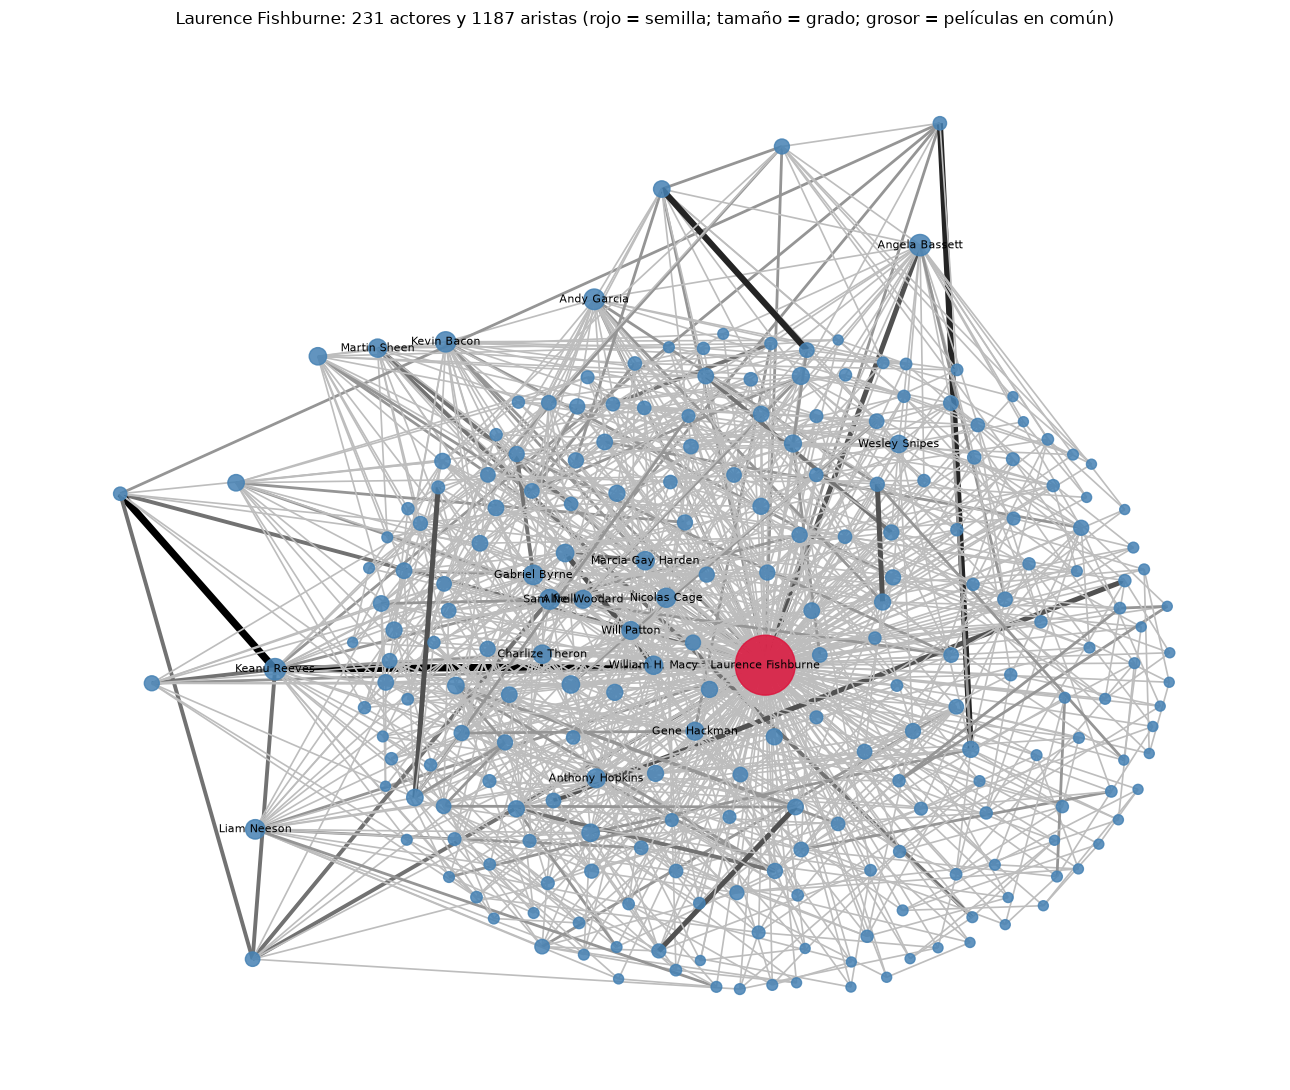

In [6]:
G = nx.from_numpy_array(A)
G = nx.relabel_nodes(G, dict(enumerate(orden)))
coords = nx.kamada_kawai_layout(G)
fig, ax = plt.subplots(figsize=(13, 11))
pesos = np.array([G[u][v]["weight"] for u, v in G.edges])
nx.draw_networkx_edges(G, coords, ax=ax, width=0.4 + 0.8 * pesos, edge_color=pesos, edge_cmap=plt.cm.Greys,
                       edge_vmin=-2, edge_vmax=pesos.max())
nx.draw_networkx_nodes(G, coords, ax=ax, node_size=[20 + 8 * grado[n] for n in G.nodes],
                       node_color=["crimson" if n == SEMILLA else "steelblue" for n in G.nodes], alpha=0.85)
mayores = sorted(grado, key=grado.get, reverse=True)[:18]
nx.draw_networkx_labels(G, coords, {n: g.names[n] for n in mayores}, font_size=8, ax=ax)
ax.set_title(f"{ACTOR}: {g.total_nodes()} actores y {g.total_edges()} aristas (rojo = semilla; tamaño = grado; "
             "grosor = películas en común)")
ax.axis("off")
fig.tight_layout()
fig.savefig("figuras/grafo_fishburne.png", dpi=160)
plt.show()